In [1]:
import pennylane as qml
from pennylane import numpy as np
from pennylane.optimize import AdamOptimizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.kernel_approximation import PolynomialCountSketch
from sklearn.linear_model import LogisticRegression, SGDClassifier
from itertools import combinations_with_replacement, product
from sympy.physics.quantum.tensorproduct import TensorProduct
import matplotlib.pyplot as plt
from functools import reduce
from pprint import pprint 
import sympy as sp
from random import random, shuffle, randrange, sample
import math
import pickle
import copy
from datetime import datetime

Data generation:


In [2]:
def generate_graph(vertex_count, is_connected, p):
    """
    Generates a random graph with the specified number of vertices and edges.
    The graph is represented by adjecency matrix.
    The graph can be connected or disconnected.
    The parameter `p` determines how much the graph is "connected", where for
    connected graphs p=1 means fully connected and p=0 means no extra edges.
    For disconnected graphs, p=1 means that the graph is comprised of 2 partitions,
    whereas p=0 means that the graph is completely disconnected (there are no edges).
    """
    if vertex_count <= 0:
        raise ValueError("vertex_count must be a positive integer.")
    
    adj_matrix = np.zeros((vertex_count, vertex_count), dtype=int)

    if vertex_count == 1: # A single-vertex graph has no edges.
        return adj_matrix # Returns [[0]]

    if is_connected:
        # Build a random spanning tree to ensure connectivity.
            order = list(range(vertex_count))
            shuffle(order)
            for i in range(1, vertex_count):
                j = randrange(i) # Randomly select a parent node
                u, v = order[i], order[j]
                # Fill both, since it's undirected
                adj_matrix[u, v] = 1
                adj_matrix[v, u] = 1
            
            if p > 0:
                # Add additional edges to increase density
                for i in range(vertex_count):
                    for j in range(i + 1, vertex_count):
                        if adj_matrix[i, j] == 0 and random() < p:
                            # Fill both, since it's undirected
                            adj_matrix[i, j] = 1
                            adj_matrix[j, i] = 1
    else:
        # The more partition the more disconnected it is.
        partitions = max(math.floor(vertex_count * (1 - p)), 2)
        cuts = sorted(sample(range(1, vertex_count), partitions - 1))
        cuts = [0] + cuts + [vertex_count]   
        cut_sizes = [cuts[i + 1] - cuts[i] for i in range(len(cuts) - 1)]
        nodes = list(range(vertex_count))     
        shuffle(nodes)
        
        partition_sets = []
        size_id = 0
        for size in cut_sizes:
            partition_sets.append(nodes[size_id:size_id + size])
            size_id += size
        
        # Build the matrix
        for part in partition_sets:
            for i in range(len(part)):
                for j in range(i + 1, len(part)):
                    u, v = part[i], part[j]
                    
                    # Fill both, since it's undirected
                    adj_matrix[u, v] = 1
                    adj_matrix[v, u] = 1
    
    return (adj_matrix, int(is_connected))

def generate_data(
    num_samples,
    vertex_count,
    connected_label_ratio=0.5,
    density_mean=0.5,  
    density_std_dev=0.1 # Standard deviation for the distribution
):
    """
    Generate random graph data using the generate_graph function.
    Each sample is a tuple of (adjacency matrix, label).
    The label is a binary classification based on whether it's connected (1)
    or disconnected (0).
    For disconnected graphs, connectivity is sampled from a normal distribution
    with `disconnected_density` as the mean and `disconnected_density_std_dev`
    as the standard deviation, clipped to [0, 1).
    """
    if not (0 <= connected_label_ratio <= 1):
        raise ValueError("label_1_ratio must be between 0 and 1.")
    if not (0 <= density_mean < 1):
        # disconnected_density (mean) must be between 0 (inclusive) and 1 (exclusive).
        raise ValueError("disconnected_density_mean (mean) must be between 0 (inclusive) and 1 (exclusive).")
    if density_std_dev < 0:
        raise ValueError("disconnected_density_std_dev must be non-negative.")

    data = []
    num_label_1 = int(round(num_samples * connected_label_ratio))
    
    # Get how dense the graph should be
    # Clipped to ensure 0 <= sample < 1
    get_density_graph = lambda:  np.clip(np.random.normal(
            loc=density_mean, 
            scale=density_std_dev
        ), 0.0, 0.999999)
    
    for index in range(num_samples):
        is_connected = 1 if index < num_label_1 else 0
        adj_matrix, label = generate_graph(vertex_count, is_connected, get_density_graph())
        data.append((adj_matrix, label))

    # Shuffle the data to ensure that samples of different labels are mixed.
    np.random.shuffle(data)
    
    return data


def is_graph_connected(adj_matrix):
    """
    Check if the graph represented by the adjacency matrix is connected.
    Uses a depth-first search (DFS) approach.
    """
    n = adj_matrix.shape[0]
    visited = np.zeros(n, dtype=bool)

    def dfs(v):
        visited[v] = True
        for u in range(n):
            if adj_matrix[v, u] == 1 and not visited[u]:
                dfs(u)

    # Start DFS from the first vertex
    dfs(0)
    
    return np.all(visited)

def verify_dataset(data):
    """
    Verify the dataset to ensure that the labels are correct.
    This function checks if the generated graphs are connected or not
    based on their adjacency matrices.
    """
    for adj_matrix, label in data:
        if is_graph_connected(adj_matrix) != bool(label):
            print("Dataset verification failed.")
            print(f"Adjacency matrix:\n{adj_matrix}")
            print(f"Expected label: {label}, but got: {int(is_graph_connected(adj_matrix))}")
            return False
    print("Dataset verified successfully.")
    return True

def compute_accuracy(predicted_labels, true_labels):
    """
    Compute the accuracy of the predictions.
    """
    return np.mean(predicted_labels == true_labels)

#### Verify data set

In [3]:
num_samples_verify = 10000
vertex_count = 10

raw_data = generate_data(
    num_samples=num_samples_verify,
    vertex_count=vertex_count,
    connected_label_ratio=0.5,
    density_mean=0.5,
    density_std_dev=0.1
)

if not verify_dataset(raw_data):
    raise ValueError("Dataset verification failed.")

Dataset verified successfully.


# Quantum model

In [4]:
N=4
# dev = qml.device("default.qubit", wires=N)
dev = qml.device("lightning.gpu", wires=N)


def create_Hg(adjacency_matrix, gamma_param=None):
    """
    Create a Hamiltonian for the given adjacency matrix.
    The Hamiltonian is represented as a sum of Pauli operators.
    """
    num_qubits = adjacency_matrix.shape[0]
    coef, terms = [], []
    for i in range(num_qubits):
        for j in range(i + 1, num_qubits):
            if adjacency_matrix[i, j] == 1:
                coef.append(1.0 if gamma_param is None else gamma_param)
                terms.append(qml.PauliZ(wires=i) @ qml.PauliZ(wires=j))
    return qml.Hamiltonian(coeffs=coef, observables=terms)

def create_data_encoding_block(adjacency_matrix, gamma_param=None):
    """
    Create a data encoding block for the given adjacency matrix.
    """
    H = create_Hg(adjacency_matrix, gamma_param)
    if len(H.wires) == 0:
        """
        Leave identity operation
        """
        # qml.Identity(wires=range(N))
    else:
        qml.ApproxTimeEvolution(
            H,
            time=1.0,
            n=3,
        )

def create_parameterized_block(thetas, N):
    for i in range(N):
        if len(thetas) >= 1:
            qml.RX(thetas[0], wires=i)
        if len(thetas) >= 2:
            qml.RY(thetas[1], wires=i)
        if len(thetas) >= 3:
            qml.RZ(thetas[2], wires=i)

@qml.qnode(dev, interface="autograd")
def normal_circuit(theta_params, gamma_params, adjacency_matrix, measurement_op):
    """
    Quantum circuit for the quantum graph classifier.
    """
    is_gamma_none = gamma_params is None
    if is_gamma_none:
        gamma_params = [None] * len(theta_params)

    for theta, gamma in zip(theta_params, gamma_params):
        create_parameterized_block(theta, adjacency_matrix.shape[0])
        create_data_encoding_block(adjacency_matrix, gamma)
    
    return qml.expval(qml.Hermitian(measurement_op, wires=[0]))

In [5]:

# Test out the circuit
layers = 3
thetas = np.random.randn(layers, 1)
gammas = np.random.randn(layers)
theta_params = np.array(thetas, requires_grad=True)
gamma_params = np.array(gammas, requires_grad=True)
print(theta_params)
print(gamma_params)
m_op = np.array([[1], [0]] @ np.conj([[1], [0]]).T)
adj_matrix = np.array([
    [0, 1, 1, 0],
    [1, 0, 0, 1],
    [1, 0, 0, 1],
    [0, 1, 1, 0]
])

demo_dev = qml.device("default.qubit", wires=4)
# data = format_param_data(params)
print(qml.QNode(normal_circuit, demo_dev)(theta_params, None, adj_matrix, m_op))
print(qml.QNode(normal_circuit, demo_dev)(theta_params, gamma_params, adj_matrix, m_op))

[[-0.87478222]
 [ 0.62591123]
 [ 0.49338557]]
[-0.92539578  1.91511347  0.11235936]


/home/zdrav/Desktop/aqa/proect/.venv/lib/python3.13/site-packages/pennylane/devices/preprocess.py:286: UserWarning: Differentiating with respect to the input parameters of Hermitian is not supported with the adjoint differentiation method. Gradients are computed only with regards to the trainable parameters of the circuit.

 Mark the parameters of the measured observables as non-trainable to silence this warning.
  warnings.warn(


0.6517122614751404
0.5537998973066665


[(<Figure size 900x500 with 1 Axes>, <Axes: >)]

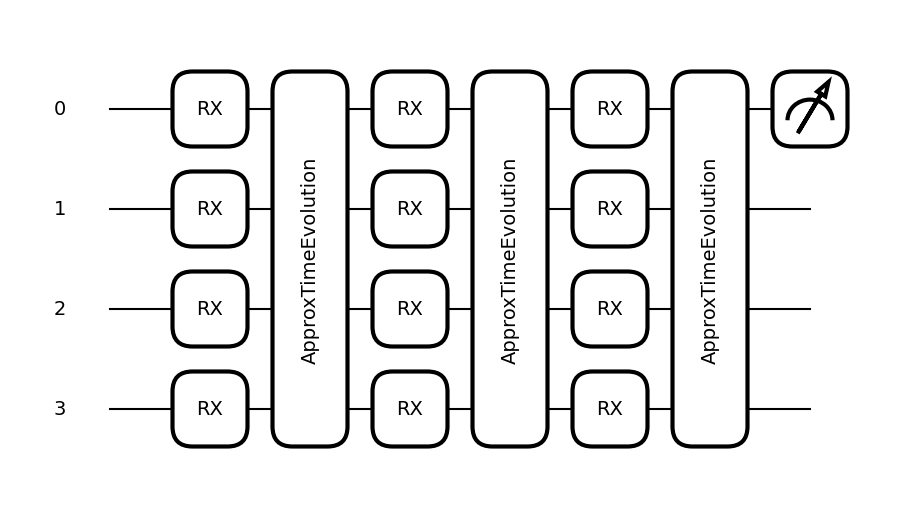

In [6]:

layers = 3
thetas = np.random.randn(layers, 1)
theta_params = np.array(thetas, requires_grad=True)
gammas = np.random.randn(layers)
gamma_params = np.array(gammas, requires_grad=True)
params = theta_params
adj_matrix = np.array([
    [0, 1, 1, 0],
    [1, 0, 0, 1],
    [1, 0, 0, 1],
    [0, 1, 1, 0]
])


m_op = np.array([[1], [0]] @ np.conj([[1], [0]]).T)
demo_dev = qml.device("default.qubit", wires=4)

demo_qnode = qml.QNode(normal_circuit.func, demo_dev)


qml.draw_mpl(
    demo_qnode,
    show_all_wires=True,
    max_length=20,
    lavel="device",
    expansion_strategy="device",
)(
    params,
    gamma_params,
    adj_matrix,
    m_op,
)

In [7]:


m_op_label_0 = [[1], [0]]
m_op_label_1 = [[0], [1]]


measurement_ops = np.array([
    m_op_label_0 * np.conj(m_op_label_0).T,
    m_op_label_1 * np.conj(m_op_label_1).T,    
])

def cost(circuit, theta_params, gamma_params, adjacency_matrices, labels):
    """
    Cost function for the quantum graph classifier.
    """
    loss = 0
    for A, label in zip(adjacency_matrices, labels):
        fidelity = circuit(theta_params, gamma_params, A, measurement_ops[label])
        loss += (1 - fidelity) ** 2
    return loss / len(adjacency_matrices)

def test(circuit, theta_params, gamma_params, adjacency_matrices):
    """
    Run the quantum circuit and compute the cost.
    """
    predictions = []
    fidelity_values = []
    
    for A in adjacency_matrices:
        fidelity_0 = circuit(theta_params, gamma_params, A, measurement_ops[0])
        fidelities = [fidelity_0, 1 - fidelity_0]
        predictions.append(np.argmax(fidelities))
        fidelity_values.append(fidelities)
    return np.array(predictions), np.array(fidelity_values)

def random_batch(samples, labes, batch_size):
    """
    Generate a random batch of data.
    """
    indices = np.random.choice(len(samples), size=batch_size, replace=False)
    return [samples[i] for i in indices], [labes[i] for i in indices]

In [5]:
# Run test on train_qml_model
num_samples = 1000

raw_data = generate_data(
    num_samples=num_samples,
    vertex_count=N,
    connected_label_ratio=0.5,
    density_mean=0.5,
    density_std_dev=0.1
)

if not verify_dataset(raw_data):
    raise ValueError("Dataset verification failed.")

X_raw = np.array([data_point[0] for data_point in raw_data])
y_raw = np.array([data_point[1] for data_point in raw_data])

train_data, test_data, train_label, test_label = train_test_split(
    X_raw,
    y_raw,
    test_size=0.3,
    random_state=42,
    stratify=y_raw,
)


Dataset verified successfully.


In [5]:


def train_qml_model(
    circuit,
    train_data_tuple,
    test_data_tuple,
    epochs=6,
    ansatz_layers=1,
    ansatz_params=1,
    hamiltonian_params=0,
    convergence_buffer=5,
    convergence_threshold=0.01,
    sample_size_cost_batch=100,
):
    """
    Train the quantum model.
    """
    train_data, train_label = train_data_tuple
    test_data, test_label = test_data_tuple
    
    results = []
    batch_size = 32
    step_size = 0.2
    train_sample_size_batch = min(len(train_data), sample_size_cost_batch)
    test_sample_size_batch = min(len(test_data), sample_size_cost_batch)
    
    optimizer = AdamOptimizer(
        step_size,
        beta1=0.9,
        beta2=0.999,
        # eps=1e-8,
    )
    
    # Initial parameters
    thetas = np.random.randn(ansatz_layers, ansatz_params)
    theta_params = np.array(thetas, requires_grad=True)
    gamma_params = None
    if hamiltonian_params > 0:
        gamma_params = np.random.randn(ansatz_layers)
        gamma_params = np.array(gamma_params, requires_grad=True)
        
        
    # Create batches
    train_batch_data, train_batch_label = random_batch(train_data, train_label, train_sample_size_batch)
    test_batch_data, test_batch_label = random_batch(test_data, test_label, test_sample_size_batch)


    # Create initial predictions
    predicted_labels_test, fidelity_values_test = test(circuit, theta_params, gamma_params, test_batch_data)
    test_accuracy = compute_accuracy(predicted_labels_test, test_batch_label)

    # predicted_labels_train, fidelity_values_train = test(circuit, theta_params, train_data)
    # train_accuracy = compute_accuracy(predicted_labels_train, train_label)
    loss = cost(circuit, theta_params, gamma_params, train_batch_data, train_batch_label)
    
    batch_result = [copy.deepcopy(list([theta_params, gamma_params])), test_accuracy, loss]

    results.append(batch_result)
    
    
    progress_msg = f"Epoch {0:2d}  test_acc={test_accuracy:.3f} loss={loss:.3f}"
    print(progress_msg)
    
    convergence_limit = 0
    
    epochs_finished = 0
    for epoch in range(epochs):
        # Prepare batches of data
        for start in range(0, len(train_data), batch_size):
            A_batch = train_data[start:start+batch_size]
            y_batch = train_label[start:start+batch_size]
            if hamiltonian_params == 0:
                theta_params = optimizer.step(lambda th: cost(circuit, th, None, A_batch, y_batch), theta_params)
            else:
                theta_params, gamma_params = optimizer.step(
                    lambda th, gm: cost(circuit, th, gm, A_batch, y_batch),
                    theta_params, gamma_params
                )
                
        
        train_batch_data, train_batch_label = random_batch(train_data, train_label, train_sample_size_batch)
        test_batch_data, test_batch_label = random_batch(test_data, test_label, test_sample_size_batch)

        
        predicted_labels_test, fidelity_values_test = test(circuit, theta_params, gamma_params, test_batch_data)
        test_accuracy = compute_accuracy(predicted_labels_test, test_batch_label)

        # predicted_labels_train, fidelity_values_train = test(circuit, theta_params, train_data)
        # train_accuracy = compute_accuracy(predicted_labels_train, train_label)
        loss = cost(circuit, theta_params, gamma_params, train_batch_data, train_batch_label)
        batch_result = [copy.deepcopy(list([theta_params, gamma_params])), test_accuracy, loss]
        
        results.append(batch_result)
        progress_msg = f"Epoch {epoch+1:2d}  test_acc={test_accuracy:.3f} loss={loss:.3f}"
        print(progress_msg)
        
        if abs(loss - results[epochs_finished][2]) <= convergence_threshold:
            convergence_limit += 1
        else:
            convergence_limit = 0
            
        if convergence_limit >= convergence_buffer or epoch == epochs - 1:
            predicted_labels_test, fidelity_values_test = test(circuit, theta_params, gamma_params, test_data)
            test_accuracy = compute_accuracy(predicted_labels_test, test_label)
            loss = cost(circuit, theta_params, gamma_params, train_data, train_label)
            batch_result = [copy.deepcopy(list([theta_params, gamma_params])), test_accuracy, loss]
            results.append(batch_result)
            print(f"Final test_acc={test_accuracy:.3f} loss={loss:.3f}")
            print(f"Convergence limit reached")
            break
        
        epochs_finished += 1
        
    return results, (theta_params, gamma_params), epochs_finished
    

In [6]:

def train_classical_model(tr_data, tr_label, layers):
    num_samples = len(tr_data)
    if num_samples == 0:
        raise ValueError("Input array is empty.")
    

    data_tr = tr_data.reshape(num_samples, -1)
    # A_poly = build_polynomial_features(data, layers)
    poly = None
    clf = None
    # For layers < 4, build exact polynomial features
    # For layers >= 4, approximate using polynomial count sketch 
    if layers < 4:
        poly = PolynomialFeatures(
            degree=layers,
            interaction_only=True,
        )
        clf = LogisticRegression(
            penalty=None,
            solver='lbfgs',
            max_iter=1000,
            fit_intercept=False,
            verbose=1,
        )
    else:
        poly = PolynomialCountSketch(degree=layers, n_components=12000)
        clf = SGDClassifier(
            loss='log_loss',
            penalty='l2',
            max_iter=10000,
            tol=1e-3,
            verbose=1
        )
   
    
    A_poly = poly.fit_transform(data_tr)        
    clf.fit(A_poly, tr_label)
    return clf, poly

def test_classical_model(clf, poly, test_data, test_labels):
    num_samples = len(test_data)
    if num_samples == 0:
        raise ValueError("Input array is empty.")
    
    data = test_data.reshape(num_samples, -1)

    A_poly = poly.transform(data)
    test_acc = clf.predict(A_poly)
    test_acc = compute_accuracy(test_acc, test_labels)

    return test_acc

In [9]:
layers = 3
clf, poly = train_classical_model(train_data, train_label, layers=layers)

train_acc = test_classical_model(clf, poly, train_data, train_label)
test_acc = test_classical_model(clf, poly, test_data, test_label)

print(f"(Layers: {layers})Classical model train accuracy: {train_acc:.3f}")
print(f"(Layers: {layers})Classical model test accuracy: {test_acc:.3f}")

layers = 6
clf, poly = train_classical_model(train_data, train_label, layers=layers)

train_acc = test_classical_model(clf, poly, train_data, train_label)
test_acc = test_classical_model(clf, poly, test_data, test_label)

print(f"(Layers: {layers})Classical model train accuracy: {train_acc:.3f}")
print(f"(Layers: {layers})Classical model test accuracy: {test_acc:.3f}")



[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.2s finished


(Layers: 3)Classical model train accuracy: 1.000
(Layers: 3)Classical model test accuracy: 0.997
-- Epoch 1
Norm: 7385.94, NNZs: 12000, Bias: -101.729575, T: 700, Avg. loss: 3083.108390
Total training time: 0.01 seconds.
-- Epoch 2
Norm: 5230.81, NNZs: 12000, Bias: -101.729575, T: 1400, Avg. loss: 0.000000
Total training time: 0.01 seconds.
-- Epoch 3
Norm: 4049.28, NNZs: 12000, Bias: -101.729575, T: 2100, Avg. loss: 0.000000
Total training time: 0.02 seconds.
-- Epoch 4
Norm: 3303.16, NNZs: 12000, Bias: -101.729575, T: 2800, Avg. loss: 0.000000
Total training time: 0.03 seconds.
-- Epoch 5
Norm: 2789.22, NNZs: 12000, Bias: -101.729575, T: 3500, Avg. loss: 0.000000
Total training time: 0.03 seconds.
-- Epoch 6
Norm: 2413.68, NNZs: 12000, Bias: -101.729575, T: 4200, Avg. loss: 0.000000
Total training time: 0.04 seconds.
-- Epoch 7
Norm: 2127.26, NNZs: 12000, Bias: -101.729575, T: 4900, Avg. loss: 0.000000
Total training time: 0.05 seconds.
Convergence after 7 epochs took 0.05 seconds
(L

In [12]:
# number of polynomials with k=9 layers
math.comb(10**2 + 9 - 1, 9)

3911395881900

In [ ]:
results, theta_params, epochs = train_qml_model(
    normal_circuit,
    (train_data, train_label),
    (test_data, test_label),
    epochs=30,
    ansatz_layers=layers,
    ansatz_params=1,
    hamiltonian_params=0,
    convergence_buffer=3,
)


results, theta_params, epochs = train_qml_model(
    normal_circuit,
    (train_data, train_label),
    (test_data, test_label),
    epochs=30,
    ansatz_layers=layers,
    ansatz_params=1,
    hamiltonian_params=1,
    convergence_buffer=3,
)


/home/zdrav/Desktop/aqa/proect/.venv/lib/python3.13/site-packages/pennylane/devices/preprocess.py:286: UserWarning: Differentiating with respect to the input parameters of Hermitian is not supported with the adjoint differentiation method. Gradients are computed only with regards to the trainable parameters of the circuit.

 Mark the parameters of the measured observables as non-trainable to silence this warning.
  warnings.warn(


Epoch  0  test_acc=0.480 loss=0.305
Epoch  1  test_acc=0.910 loss=0.146
Epoch  2  test_acc=0.950 loss=0.081
Epoch  3  test_acc=0.960 loss=0.062
Epoch  4  test_acc=0.960 loss=0.066
Epoch  5  test_acc=0.940 loss=0.048
Epoch  6  test_acc=0.950 loss=0.059
Epoch  7  test_acc=0.970 loss=0.057
Epoch  8  test_acc=0.960 loss=0.056
Epoch  9  test_acc=0.970 loss=0.055
Final test_acc=0.957 loss=0.058
Convergence limit reached
Epoch  0  test_acc=0.680 loss=0.252
Epoch  1  test_acc=0.840 loss=0.146
Epoch  2  test_acc=0.830 loss=0.100
Epoch  3  test_acc=0.970 loss=0.080
Epoch  4  test_acc=0.990 loss=0.067
Epoch  5  test_acc=1.000 loss=0.054
Epoch  6  test_acc=0.990 loss=0.052
Epoch  7  test_acc=0.980 loss=0.060
Epoch  8  test_acc=0.960 loss=0.051
Final test_acc=0.950 loss=0.063
Convergence limit reached


# Check permutation equvariance

In [13]:
N_comm_check = 6

# Compute commutation relations
complete_adjecency_matrix = sp.Matrix([[0, 1], [1, 0]])
Y = sp.Matrix([[0, -1j], [1j, 0]])
Z = sp.Matrix([[1, 0], [0, -1]])
I2 = sp.Matrix([[1, 0], [0, 1]])

# One-qubit rotation constructors
def RX(theta):
    return sp.cos(theta/2)*I2 - sp.I*sp.sin(theta/2)*complete_adjecency_matrix

def RY(theta):
    return sp.cos(theta/2)*I2 - sp.I*sp.sin(theta/2)*Y

def RZ(theta):
    return sp.cos(theta/2)*I2 - sp.I*sp.sin(theta/2)*Z


def mq_unitary(op, index, index2=None):
    """
    Multi-qubit unitary operator
    """
    return TensorProduct(
        *[op if i == index or i == index2 else I2 for i in range(N_comm_check)]
    )

def Rx_fn():
    op = RX(sp.symbols('Rx_theta'))
    return [mq_unitary(op, i) for i in range(N_comm_check)]

def RxRy_fn():
    op_X = RX(sp.symbols("RxRy_theta_0"))
    op_Y = RY(sp.symbols("RxRy_theta_1"))
    return [mq_unitary(op_X, i) @ mq_unitary(op_Y, i) for i in range(N_comm_check)]

def RxRyRz_fn():
    op_X = RX(sp.symbols("RxRyRz_theta_0"))
    op_Y = RY(sp.symbols("RxRyRz_theta_1"))
    op_Z = RZ(sp.symbols("RxRyRz_theta_2"))
    return [mq_unitary(op_X, i) @ mq_unitary(op_Y, i) @ mq_unitary(op_Z, i) for i in range(N_comm_check)]

def get_matrix_parametrized(arr):
    return reduce(lambda x, y: x @ y, arr)


def get_data_encoding_Hamiltonian(adjacency_matrix, index=False):
    if adjacency_matrix.shape[0] != N_comm_check:
        raise ValueError("Adjacency matrix size does not match the number of qubits.")
    symb = 1 if index == False else sp.symbols(f"gamma_{index}")
    eH = sp.zeros(2**N_comm_check, 2**N_comm_check)
    
    
    
    for i in range(N_comm_check):
        for j in range(i + 1, N_comm_check):
            if adjacency_matrix[i, j] == 1:
                eH +=(symb/2)* mq_unitary(Z, i, j)
    
    return (sp.I * eH).exp()
    
def get_swaps():
    matrices = []
    for i in range(N_comm_check):
        for j in range(i + 1, N_comm_check):
            matrices.append(qml.matrix(qml.SWAP(wires=[i, j]), wire_order=range(N_comm_check)))
    return matrices

def generate_adjacency_matrices():
    # Bin dist for number of edges
    num_edges = N_comm_check * (N_comm_check - 1) // 2
    matrices = []
    for bits in product([0, 1], repeat=num_edges):
        matrix = [[0] * N_comm_check for _ in range(N_comm_check)]
        idx = 0
        # Fill upper triangle and mirror
        for i in range(N_comm_check):
            for j in range(i + 1, N_comm_check):
                val = bits[idx]
                matrix[i][j] = val
                matrix[j][i] = val
                idx += 1
        matrices.append(np.array(matrix))        
    return matrices
swaps = get_swaps()

def check_commutation(W, W_str, verbose=True):
    for i, swap in enumerate(swaps):
        C_raw = swap @ W - W @ swap
        C = C_raw.applyfunc(sp.simplify)
        if (not C.is_zero_matrix):
            print(f"{W_str} does not commute with swap")
            print(C)
            print(swap)
            break
        if i % 3 == 0 and verbose:
            print(f"{W_str}: Complete {i + 1}/{len(swaps)} checks")

    print(f"Success. {W_str} ansatz does commute with swap")
    
def check_commutation_all(W_list, W_str_list):
    for index_list, W in enumerate(W_list):
        for index, swap in enumerate(swaps):
            current_index = index * index_list
            C_raw = swap @ W - W @ swap
            C = C_raw.applyfunc(sp.simplify)
            if (not C.is_zero_matrix):
                print(f"{W_str_list} does not commute with swap {index_list}, {index}")
                pprint(C)
                pprint(swap)
                pprint(W)
                return
        if (current_index) % 3 == 0:
            print(f"{W_str_list}: Complete {current_index + 1}/{len(W_list) * len(swaps)} checks")
    print(f"Success. {W_str_list} ansatz does commute with swap")


In [14]:


W_Rx = sp.Matrix(get_matrix_parametrized(Rx_fn()))
W_RxRy = sp.Matrix(get_matrix_parametrized(RxRy_fn()))
W_RxRyRz = sp.Matrix(get_matrix_parametrized(RxRyRz_fn()))

print("Checking commutation with ansatzes")
check_commutation(W_Rx, "Rx", verbose=False)
check_commutation(W_RxRy, "RxRy", verbose=False)
check_commutation(W_RxRyRz, "RxRyRz", verbose=False)

print("Checking commutation with data encoding")
complete_adjecency_matrix = sp.Matrix([
    [
        1 if i != j else 0 for j in range(N_comm_check)
    ] for i in range(N_comm_check)
])

#Show commutation for complete graph (all swaps should commute)
M = get_data_encoding_Hamiltonian(complete_adjecency_matrix, True)
check_commutation(M, "M", verbose=False)


Checking commutation with ansatzes
Success. Rx ansatz does commute with swap
Success. RxRy ansatz does commute with swap
Success. RxRyRz ansatz does commute with swap
Checking commutation with data encoding
Success. M ansatz does commute with swap


In [13]:
graph_nodes = 10
unique_graphs = 2**(graph_nodes * (graph_nodes - 1) // 2)
print(f"Number of unique graphs: {unique_graphs}")

Number of unique graphs: 35184372088832


In [10]:

num_samples = 10000
N = 10
dev_test = qml.device("lightning.gpu", wires=N)
circuit_test = qml.QNode(normal_circuit.func, dev_test)

raw_data = generate_data(
    num_samples=num_samples,
    vertex_count=N,
    connected_label_ratio=0.5,
    density_mean=0.5,
    density_std_dev=0.1
)

if not verify_dataset(raw_data):
    raise ValueError("Dataset verification failed.")

X_raw = np.array([data_point[0] for data_point in raw_data])
y_raw = np.array([data_point[1] for data_point in raw_data])

train_data, test_data, train_label, test_label = train_test_split(
    X_raw,
    y_raw,
    test_size=0.3,
    random_state=42,
    stratify=y_raw,
)


Dataset verified successfully.


In [11]:
# Run on different layers
computed_layers = [1, 3, 6, 9, 12]
convergence_buffer = 4
convergence_threshold = 0.01

def store_res(results, file_name):
    with open(f"res/{file_name}_{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}", "wb") as f:
        pickle.dump(results, f)

In [ ]:
# Rx ansatz only
rx_results = {}
rx_results["settings"] = {
    "N": N,
    "ansatz_params": 1,
    "epochs": 100,
    "sample_size_cost_batch": 300,
    "hamiltonian_params": 0,
    "convergence_buffer": convergence_buffer,
    "convergence_threshold": convergence_threshold,
}
for layer in computed_layers:
    results, _, _ = train_qml_model(
        circuit_test,
        (train_data, train_label),
        (test_data, test_label),
        epochs=100,
        ansatz_layers=layer,
        ansatz_params=1,
        hamiltonian_params=0,
        sample_size_cost_batch=300,
        convergence_buffer=convergence_buffer,
        convergence_threshold=convergence_threshold,
    )
    rx_results[layer] = results
    print(f"Rx ansatz with {layer} layers")
    print(f"Final test accuracy: {results[-1][1]:.3f}")
    print(f"Final loss: {results[-1][2]:.3f}")
    print("=====================================")

Epoch  0  test_acc=0.503 loss=0.423
Epoch  1  test_acc=0.567 loss=0.249
Epoch  2  test_acc=0.553 loss=0.252
Epoch  3  test_acc=0.477 loss=0.250
Epoch  4  test_acc=0.493 loss=0.248
Epoch  5  test_acc=0.487 loss=0.250
Final test_acc=0.500 loss=0.250
Convergence limit reached
Rx ansatz with 1 layers
Final test accuracy: 0.500
Final loss: 0.250
Epoch  0  test_acc=0.497 loss=0.340
Epoch  1  test_acc=0.787 loss=0.206
Epoch  2  test_acc=0.850 loss=0.211
Epoch  3  test_acc=0.753 loss=0.212
Epoch  4  test_acc=0.767 loss=0.207
Epoch  5  test_acc=0.810 loss=0.216
Final test_acc=0.796 loss=0.209
Convergence limit reached
Rx ansatz with 3 layers
Final test accuracy: 0.796
Final loss: 0.209
Epoch  0  test_acc=0.777 loss=0.215
Epoch  1  test_acc=0.903 loss=0.135
Epoch  2  test_acc=0.900 loss=0.143
Epoch  3  test_acc=0.907 loss=0.132
Epoch  4  test_acc=0.903 loss=0.137
Epoch  5  test_acc=0.930 loss=0.127
Epoch  6  test_acc=0.920 loss=0.131
Epoch  7  test_acc=0.923 loss=0.138
Epoch  8  test_acc=0.877 l

In [20]:
store_res(rx_results, "rx_ansatz")

In [ ]:
# RxRy ansatz only
rxry_results = {}
rxry_results["settings"] = {
    "N": N,
    "ansatz_params": 2,
    "epochs": 100,
    "sample_size_cost_batch": 300,
    "hamiltonian_params": 0,
    "convergence_buffer": convergence_buffer,
    "convergence_threshold": convergence_threshold,
}
for layer in computed_layers:
    results, _, _ = train_qml_model(
        circuit_test,
        (train_data, train_label),
        (test_data, test_label),
        epochs=100,
        ansatz_layers=layer,
        ansatz_params=2,
        hamiltonian_params=0,
        sample_size_cost_batch=300,
        convergence_buffer=convergence_buffer,
        convergence_threshold=convergence_threshold,
    )
    rxry_results[layer] = results
    print(f"RxRy ansatz with {layer} layers")
    print(f"Final test accuracy: {results[-1][1]:.3f}")
    print(f"Final loss: {results[-1][2]:.3f}")
    print("=====================================")

Epoch  0  test_acc=0.497 loss=0.366
Epoch  1  test_acc=0.543 loss=0.250
Epoch  2  test_acc=0.517 loss=0.251
Epoch  3  test_acc=0.540 loss=0.250
Epoch  4  test_acc=0.537 loss=0.250
Epoch  5  test_acc=0.500 loss=0.251
Final test_acc=0.500 loss=0.250
Convergence limit reached
RxRy ansatz with 1 layers
Final test accuracy: 0.500
Final loss: 0.250
Epoch  0  test_acc=0.467 loss=0.264
Epoch  1  test_acc=0.940 loss=0.163
Epoch  2  test_acc=0.893 loss=0.167
Epoch  3  test_acc=0.883 loss=0.174
Epoch  4  test_acc=0.853 loss=0.168
Epoch  5  test_acc=0.870 loss=0.167
Final test_acc=0.837 loss=0.168
Convergence limit reached
RxRy ansatz with 3 layers
Final test accuracy: 0.837
Final loss: 0.168
Epoch  0  test_acc=0.633 loss=0.206
Epoch  1  test_acc=0.970 loss=0.130
Epoch  2  test_acc=0.980 loss=0.120
Epoch  3  test_acc=0.970 loss=0.114
Epoch  4  test_acc=0.980 loss=0.116
Epoch  5  test_acc=0.980 loss=0.122
Final test_acc=0.977 loss=0.120
Convergence limit reached
RxRy ansatz with 6 layers
Final test

In [23]:
store_res(rxry_results, "rxry_ansatz")

In [ ]:
# RxRyRz ansatz only
# rxryrz_results = {}
# TODO: Do not run 1,3,6,9 (already done)(stopped premmaturely)
rxryrz_results["settings"] = {
    "N": N,
    "ansatz_params": 3,
    "epochs": 100,
    "hamiltonian_params": 0,
    "convergence_buffer": convergence_buffer,
    "convergence_threshold": convergence_threshold,
}
for layer in [12]:
    results, _, _ = train_qml_model(
        circuit_test,
        (train_data, train_label),
        (test_data, test_label),
        epochs=20,
        ansatz_layers=layer,
        ansatz_params=3,
        hamiltonian_params=0,
        sample_size_cost_batch=300,
        convergence_buffer=convergence_buffer,
        convergence_threshold=0.02,
    )
    rxryrz_results[layer] = results
    print(f"RxRyRz ansatz with {layer} layers")
    print(f"Final test accuracy: {results[-1][1]:.3f}")
    print(f"Final loss: {results[-1][2]:.3f}")
    print("=====================================")

/home/zdrav/Desktop/aqa/proect/.venv/lib/python3.13/site-packages/pennylane/devices/preprocess.py:286: UserWarning: Differentiating with respect to the input parameters of Hermitian is not supported with the adjoint differentiation method. Gradients are computed only with regards to the trainable parameters of the circuit.

 Mark the parameters of the measured observables as non-trainable to silence this warning.
  warnings.warn(


Epoch  0  test_acc=0.533 loss=0.239
Epoch  1  test_acc=0.740 loss=0.120
Epoch  2  test_acc=0.740 loss=0.137
Epoch  3  test_acc=0.750 loss=0.138
Epoch  4  test_acc=0.790 loss=0.123
Epoch  5  test_acc=0.740 loss=0.128
Final test_acc=0.752 loss=0.135
Convergence limit reached
RxRyRz ansatz with 12 layers
Final test accuracy: 0.752
Final loss: 0.135


In [26]:
store_res(rxryrz_results, "rxryrz_ansatz")

In [ ]:
# Rx ansatz only
rx_H_results = {}
rx_H_results["settings"] = {
    "N": N,
    "ansatz_params": 1,
    "epochs": 20,
    "sample_size_cost_batch": 300,
    "hamiltonian_params": 1,
    "convergence_buffer": convergence_buffer,
    "convergence_threshold": 0.02,
}
for layer in computed_layers:
    results, _, _ = train_qml_model(
        circuit_test,
        (train_data, train_label),
        (test_data, test_label),
        epochs=20,
        ansatz_layers=layer,
        ansatz_params=1,
        hamiltonian_params=1,
        sample_size_cost_batch=300,
        convergence_buffer=convergence_buffer,
        convergence_threshold=0.02,
    )
    rx_H_results[layer] = results
    print(f"Rx ansatz with {layer} layers")
    print(f"Final test accuracy: {results[-1][1]:.3f}")
    print(f"Final loss: {results[-1][2]:.3f}")
    print("=====================================")

/home/zdrav/Desktop/aqa/proect/.venv/lib/python3.13/site-packages/pennylane/devices/preprocess.py:286: UserWarning: Differentiating with respect to the input parameters of Hermitian is not supported with the adjoint differentiation method. Gradients are computed only with regards to the trainable parameters of the circuit.

 Mark the parameters of the measured observables as non-trainable to silence this warning.
  warnings.warn(


Epoch  0  test_acc=0.527 loss=0.487
Epoch  1  test_acc=0.500 loss=0.250
Epoch  2  test_acc=0.480 loss=0.252
Epoch  3  test_acc=0.543 loss=0.250
Epoch  4  test_acc=0.517 loss=0.250
Epoch  5  test_acc=0.543 loss=0.250
Final test_acc=0.500 loss=0.250
Convergence limit reached
Rx ansatz with 1 layers
Final test accuracy: 0.500
Final loss: 0.250
Epoch  0  test_acc=0.520 loss=0.202
Epoch  1  test_acc=0.830 loss=0.154
Epoch  2  test_acc=0.880 loss=0.159
Epoch  3  test_acc=0.753 loss=0.151
Epoch  4  test_acc=0.727 loss=0.154
Epoch  5  test_acc=0.833 loss=0.148
Final test_acc=0.842 loss=0.138
Convergence limit reached
Rx ansatz with 3 layers
Final test accuracy: 0.842
Final loss: 0.138
Epoch  0  test_acc=0.800 loss=0.177
Epoch  1  test_acc=0.767 loss=0.148
Epoch  2  test_acc=0.867 loss=0.137
Epoch  3  test_acc=0.883 loss=0.124
Epoch  4  test_acc=0.870 loss=0.120
Epoch  5  test_acc=0.807 loss=0.151
Epoch  6  test_acc=0.850 loss=0.112
Epoch  7  test_acc=0.827 loss=0.123
Epoch  8  test_acc=0.747 l

In [28]:
store_res(rx_H_results, "rx_H_ansatz")

In [ ]:
# RxRy ansatz only
#DO NOT RUN (done on copy 1)
rxry_H_results = {}
rxry_H_results["settings"] = {
    "N": N,
    "ansatz_params": 2,
    "epochs": 100,
    "sample_size_cost_batch": 300,
    "hamiltonian_params": 1,
    "convergence_buffer": convergence_buffer,
    "convergence_threshold": convergence_threshold,
}
for layer in computed_layers:
    results, _, _ = train_qml_model(
        circuit_test,
        (train_data, train_label),
        (test_data, test_label),
        epochs=100,
        ansatz_layers=layer,
        ansatz_params=2,
        hamiltonian_params=1,
        sample_size_cost_batch=300,
        convergence_buffer=convergence_buffer,
        convergence_threshold=0.02,
    )
    rxry_H_results[layer] = results
    print(f"RxRy ansatz with {layer} layers")
    print(f"Final test accuracy: {results[-1][1]:.3f}")
    print(f"Final loss: {results[-1][2]:.3f}")
    print("=====================================")

In [ ]:
store_res(rxry_H_results, "rxry_H_ansatz")

In [ ]:
# RxRyRz ansatz only
rxryrz_H_results = {}
rxryrz_H_results["settings"] = {
    "N": N,
    "ansatz_params": 3,
    "epochs": 100,
    "hamiltonian_params": 1,
    "convergence_buffer": 3,
    "convergence_threshold": 0.02,
}
for layer in computed_layers:
    results, _, _ = train_qml_model(
        circuit_test,
        (train_data, train_label),
        (test_data, test_label),
        epochs=10,
        ansatz_layers=layer,
        ansatz_params=3,
        hamiltonian_params=1,
        sample_size_cost_batch=300,
        convergence_buffer=3,
        convergence_threshold=0.02,
    )
    rxryrz_H_results[layer] = results
    print(f"RxRyRz ansatz with {layer} layers")
    print(f"Final test accuracy: {results[-1][1]:.3f}")
    print(f"Final loss: {results[-1][2]:.3f}")
    print("=====================================")

/home/zdrav/Desktop/aqa/proect/.venv/lib/python3.13/site-packages/pennylane/devices/preprocess.py:286: UserWarning: Differentiating with respect to the input parameters of Hermitian is not supported with the adjoint differentiation method. Gradients are computed only with regards to the trainable parameters of the circuit.

 Mark the parameters of the measured observables as non-trainable to silence this warning.
  warnings.warn(


Epoch  0  test_acc=0.463 loss=0.392
Epoch  1  test_acc=0.493 loss=0.251
Epoch  2  test_acc=0.507 loss=0.250
Epoch  3  test_acc=0.497 loss=0.250
Epoch  4  test_acc=0.487 loss=0.250
Final test_acc=0.500 loss=0.250
Convergence limit reached
RxRyRz ansatz with 1 layers
Final test accuracy: 0.500
Final loss: 0.250
Epoch  0  test_acc=0.523 loss=0.437
Epoch  1  test_acc=0.800 loss=0.144
Epoch  2  test_acc=0.757 loss=0.168
Epoch  3  test_acc=0.910 loss=0.137
Epoch  4  test_acc=0.840 loss=0.139
Epoch  5  test_acc=0.900 loss=0.124
Epoch  6  test_acc=0.863 loss=0.122
Final test_acc=0.855 loss=0.121
Convergence limit reached
RxRyRz ansatz with 3 layers
Final test accuracy: 0.855
Final loss: 0.121
Epoch  0  test_acc=0.557 loss=0.285
Epoch  1  test_acc=0.767 loss=0.149
Epoch  2  test_acc=0.790 loss=0.158
Epoch  3  test_acc=0.780 loss=0.142
Epoch  4  test_acc=0.677 loss=0.165
Epoch  5  test_acc=0.870 loss=0.127
Epoch  6  test_acc=0.933 loss=0.111
Epoch  7  test_acc=0.833 loss=0.190
Epoch  8  test_acc

In [31]:
store_res(rxryrz_H_results, "rxryrz_H_ansatz")

In [12]:
def train_and_evaluate(
    train_tuple,
    test_tuple,
    layers,
):
    train_data, train_label = train_tuple
    test_data, test_label = test_tuple
    clf, poly= train_classical_model(train_data, train_label, layers=layers)

    # train_acc = test_classical_model(clf, train_data, train_label, layers=layers)
    test_acc = test_classical_model(clf, poly, test_data, test_label)

    # print(f"Classical model train accuracy: {train_acc:.3f}")
    print(f"Classical model test accuracy: {test_acc:.3f}")
    return test_acc

In [13]:
rx_classic = {}

for layer in computed_layers:
    rx_classic[layer] = train_and_evaluate(
        (train_data, train_label),
        (test_data, test_label),
        layers=layer,
        # Too slow, because it runs out of memory and its too slow because
        # it has to access the swap file
    )
    print(f"Rx ansatz with {layer} layers")
    # print(f"Final test accuracy: {rx_classic[layer]:.3f}")
    print("=====================================")

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s finished


Classical model test accuracy: 0.938
Rx ansatz with 1 layers


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   16.0s finished


Classical model test accuracy: 0.968
Rx ansatz with 3 layers
-- Epoch 1
Norm: 2440933.02, NNZs: 12000, Bias: -3502.519721, T: 7000, Avg. loss: 404704076.951764
Total training time: 0.07 seconds.
-- Epoch 2
Norm: 1573963.39, NNZs: 12000, Bias: -4181.228606, T: 14000, Avg. loss: 47382019.748849
Total training time: 0.13 seconds.
-- Epoch 3
Norm: 1170068.47, NNZs: 12000, Bias: -4577.155380, T: 21000, Avg. loss: 17343770.931525
Total training time: 0.19 seconds.
-- Epoch 4
Norm: 890063.34, NNZs: 12000, Bias: -4766.926263, T: 28000, Avg. loss: 1960690.752374
Total training time: 0.24 seconds.
-- Epoch 5
Norm: 755751.38, NNZs: 12000, Bias: -4887.348354, T: 35000, Avg. loss: 2952528.313690
Total training time: 0.29 seconds.
-- Epoch 6
Norm: 654551.96, NNZs: 12000, Bias: -4992.784349, T: 42000, Avg. loss: 2518630.616251
Total training time: 0.35 seconds.
-- Epoch 7
Norm: 563325.84, NNZs: 12000, Bias: -5065.450771, T: 49000, Avg. loss: 353894.577274
Total training time: 0.41 seconds.
-- Epoch 8

In [14]:
store_res(rx_classic, "rx_classic")

## Process data

In [7]:
data_classic = None

data_rx = None
data_rxry = None
data_rxryrz = None
data_rx_H = None
data_rxry_H = None
data_rxryrz_H = None


with open(f"res/rx_classic_2025-05-18 21:56:51", "rb") as f:
        data_classic = pickle.load(f)
############
with open(f"res/rx_ansatz_2025-05-15 19:23:46", "rb") as f:
        data_rx = pickle.load(f)
with open(f"res/rxry_ansatz_2025-05-16 05:51:24", "rb") as f:
        data_rxry = pickle.load(f)
with open(f"res/rxryrz_ansatz_2025-05-16 21:14:01", "rb") as f:
        data_rxryrz = pickle.load(f)
############
with open(f"res/rx_H_ansatz_2025-05-18 00:57:25", "rb") as f:
        data_rx_H = pickle.load(f)
    
with open(f"res/rxry_H_ansatz_2025-05-18 01:02:03", "rb") as f:
        data_rxry_H = pickle.load(f)

with open(f"res/rxryrz_H_ansatz_2025-05-18 10:47:16", "rb") as f:
        data_rxryrz_H = pickle.load(f)

In [9]:
def convert_data(data):
    """
    Convert the data to a more usable format.
    """
    new_data = []
    for result in data:
        # accuracy, loss
        new_data.append([float(result[1]), float(result[2])])
    return new_data

def process_data(data):
    layers = [1, 3, 6, 9, 12]
    return [float(data[layer]) for layer in layers]

def get_minimum_loss_elements(data, num_datapoints=1):
    """
    Get the minimum loss elements from the data.
    """
    sorted_data = sorted(data, key=lambda x: x[1])
    return sorted_data[:num_datapoints]        

def process_qml_data(data, strategy="best-min", num_datapoints=1):
    layers = [1, 3, 6, 9, 12]
    data_points = [data[layer] for layer in layers]
    converted_data = [convert_data(data_point) for data_point in data_points]
    process_fn = None
    if strategy == "best-min":
        process_fn = lambda data_layer: get_minimum_loss_elements(data_layer, 1)[0][0]
    elif strategy == "best-avg":
        def asd(data_layer):
            d = get_minimum_loss_elements(data_layer, num_datapoints)
            d = [x[0] for x in d]
            return float(np.mean(d))
        process_fn = asd
    elif strategy == "last":
        process_fn = lambda data_layer: data_layer[-1][0]
    else:
        raise ValueError("Invalid strategy. Use 'best-min', 'best-avg', or 'last'.")
    return [process_fn(data_layer) for data_layer in converted_data]

In [17]:
# process_qml_data(data_rx, strategy="best-min", num_datapoints=1)
# process_qml_data(data_rx, strategy="best-avg", num_datapoints=4)
# process_qml_data(data_rx, strategy="last", num_datapoints=4)
# print(process_data(data_classic))

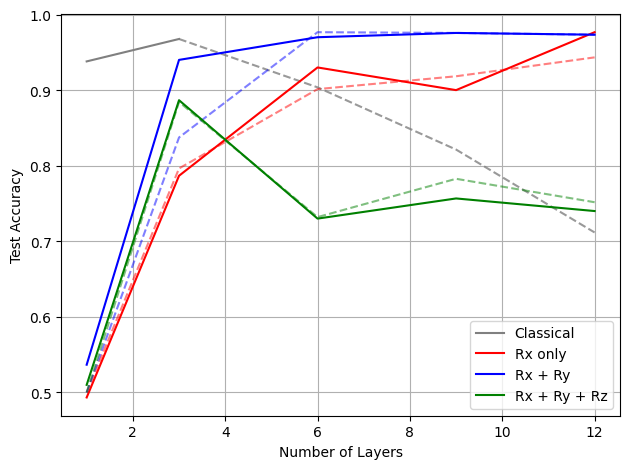

In [19]:

labels = [1,3,6,9,12]
rx_plot_data = process_qml_data(data_rx, strategy="last")
rx_plot_best = process_qml_data(data_rx, strategy="best-min")

rxry_plot_data = process_qml_data(data_rxry, strategy="last")
rxry_plot_best = process_qml_data(data_rxry, strategy="best-min")

rxryrz_plot_data = process_qml_data(data_rxryrz, strategy="last")
rxryrz_plot_best = process_qml_data(data_rxryrz, strategy="best-min")

classic = process_data(data_classic)

classic_explicit = classic[:2]
classic_approximated = classic[1:]

plt.plot(labels[:2], classic_explicit, color='gray', label='Classical')
plt.plot(labels[1:], classic_approximated, color='gray', linestyle='--', alpha=0.8)

plt.plot(labels, rx_plot_best, color='red', label='Rx only')
plt.plot(labels, rx_plot_data, color='red', linestyle='--', alpha=0.5)

plt.plot(labels, rxry_plot_best, color='blue', label='Rx + Ry')
plt.plot(labels, rxry_plot_data, color='blue', linestyle='--', alpha=0.5)

plt.plot(labels, rxryrz_plot_best, color='green', label='Rx + Ry + Rz')
plt.plot(labels, rxryrz_plot_data, color='green', linestyle='--', alpha=0.5)

plt.xlabel('Number of Layers')
plt.ylabel('Test Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

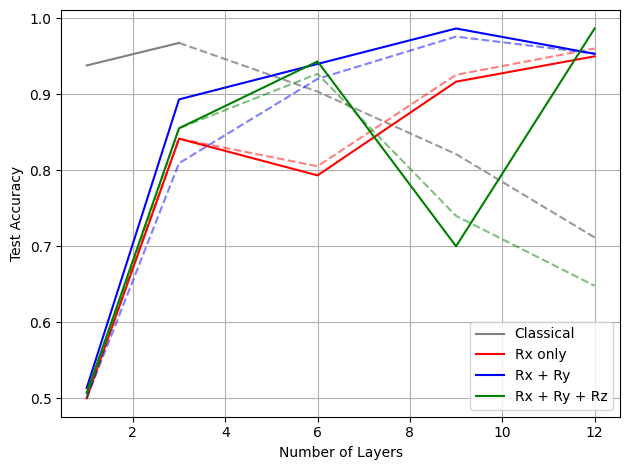

In [20]:
labels = [1,3,6,9,12]
rx_plot_data_H = process_qml_data(data_rx_H, strategy="last")
rx_plot_best_H = process_qml_data(data_rx_H, strategy="best-min")

rxry_plot_data_H = process_qml_data(data_rxry_H, strategy="last")
rxry_plot_best_H = process_qml_data(data_rxry_H, strategy="best-min")

rxryrz_plot_data_H = process_qml_data(data_rxryrz_H, strategy="last")
rxryrz_plot_best_H = process_qml_data(data_rxryrz_H, strategy="best-min")

classic = process_data(data_classic)

classic_explicit = classic[:2]
classic_approximated = classic[1:]

plt.plot(labels[:2], classic_explicit, color='gray', label='Classical')
plt.plot(labels[1:], classic_approximated, color='gray', linestyle='--', alpha=0.8)

plt.plot(labels, rx_plot_best_H, color='red', label='Rx only')
plt.plot(labels, rx_plot_data_H, color='red', linestyle='--', alpha=0.5)

plt.plot(labels, rxry_plot_best_H, color='blue', label='Rx + Ry')
plt.plot(labels, rxry_plot_data_H, color='blue', linestyle='--', alpha=0.5)

plt.plot(labels, rxryrz_plot_best_H, color='green', label='Rx + Ry + Rz')
plt.plot(labels, rxryrz_plot_data_H, color='green', linestyle='--', alpha=0.5)

plt.xlabel('Number of Layers')
plt.ylabel('Test Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()